# SEMMA Project: Iris Flower Classification

## Project Objective

The goal of this project is to classify iris flowers into three species using sepal and petal measurements. The project follows the five stages of SEMMA: Sample, Explore, Modify, Model, and Assess.

## Research Question

How accurately can a machine learning model classify iris flower species using sepal length, sepal width, petal length, and petal width?

## Dataset

**Dataset name:** Iris Flower Dataset

**Source:** https://www.kaggle.com/datasets/uciml/iris

**Task:** Multiclass classification

**Target variable:** Iris species

## Methodology

1. **Sample:** Load the dataset and create training and testing samples.
2. **Explore:** Examine the data, distributions, and relationships between features.
3. **Modify:** Prepare the features and target labels for modeling.
4. **Model:** Train machine learning classification models.
5. **Assess:** Evaluate model performance and examine classification errors.

In [1]:
# SEMMA - Step 1: Sample
# Load the Iris dataset and inspect its structure.

import pandas as pd
from sklearn.datasets import load_iris

# Load the dataset
iris = load_iris(as_frame=True)

# Create a DataFrame
df = iris.data.copy()
df["species"] = iris.target.map(
    dict(enumerate(iris.target_names))
)

# Display the first five rows
display(df.head())

# Check dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Check column names and data types
print("\nDataset information:")
df.info()

# Check for missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Check species counts
print("\nSpecies counts:")
print(df["species"].value_counts())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Number of rows: 150
Number of columns: 5

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Missing values per column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## Stage 2: Explore

The Iris dataset contains 150 observations and five columns: four numerical flower measurements and one target column identifying the species. The dataset has no missing values, and each of the three species has 50 observations.

The next step is to examine descriptive statistics and feature relationships to understand how the flower measurements differ across species. This exploration will help guide the selection and evaluation of classification models.

Summary statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50



Average measurements by species:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


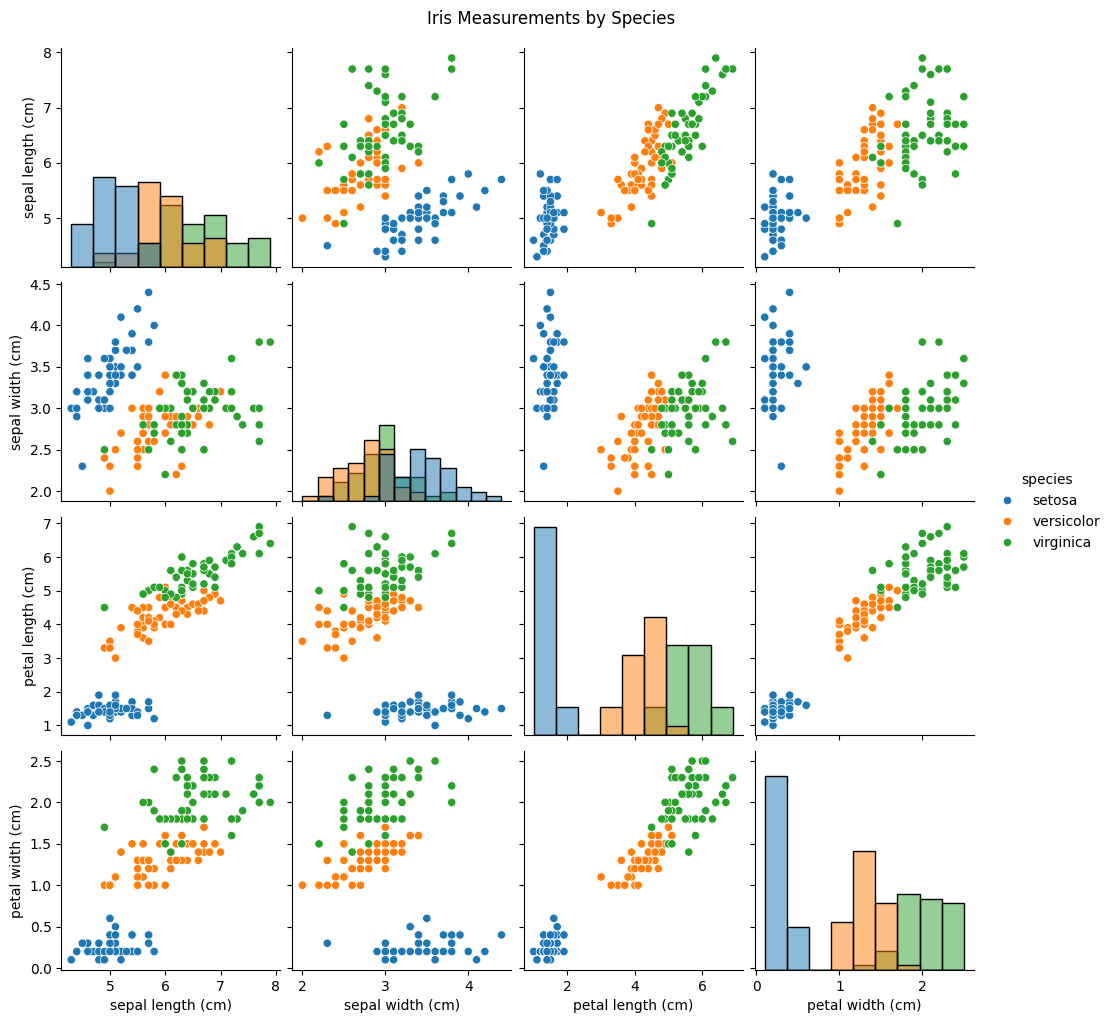

In [2]:
# SEMMA - Step 2: Explore
# Examine descriptive statistics and relationships between features.

import matplotlib.pyplot as plt
import seaborn as sns

# Summary statistics for numerical measurements
print("Summary statistics:")
display(df.describe().round(2))

# Mean measurements for each species
print("\nAverage measurements by species:")
display(
    df.groupby("species")
      .mean(numeric_only=True)
      .round(2)
)

# Visualize the relationship between measurements
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)
plt.suptitle("Iris Measurements by Species", y=1.02)
plt.show()

### Explore Stage: Findings

The descriptive statistics and pair plot provide an initial understanding of the Iris dataset. The dataset contains 150 observations, with 50 observations for each species, and no missing values were found.

The average petal length increases from setosa (1.46 cm) to versicolor (4.26 cm) and virginica (5.55 cm). Average petal width also increases across these species, from 0.25 cm for setosa to 1.33 cm for versicolor and 2.03 cm for virginica.

The pair plot shows that petal measurements separate setosa from the other species particularly well. Versicolor and virginica show some overlap, so distinguishing these two species may be more challenging.

These observations suggest that petal length and petal width will be useful features for classification. Model performance will be tested during the Model and Assess stages.

## Stage 3: Modify

In this stage, the dataset is prepared for classification. The four flower measurements will be used as input features, and the species column will be the target variable. The data will be split into training and testing sets so model performance can be evaluated on observations that were not used for training.

In [3]:
# SEMMA - Step 3: Modify
# Separate the features and target, then split the data.

from sklearn.model_selection import train_test_split

# Input features
X = df.drop(columns=["species"])

# Target labels
y = df["species"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining species counts:")
print(y_train.value_counts())

print("\nTesting species counts:")
print(y_test.value_counts())

print("\nFeature columns:")
print(X.columns.tolist())

Training samples: 120
Testing samples: 30

Training species counts:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Testing species counts:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64

Feature columns:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


### Modify Stage: Findings

The dataset was separated into four input features and one target variable, species. The data was divided into 80% training data and 20% testing data using `train_test_split`, with `random_state=42` and stratification by species.

The training set contains 120 observations, with 40 observations from each species. The testing set contains 30 observations, with 10 observations from each species.

Stratification preserves equal representation of the three species in both sets. The same four numerical measurements are used as features throughout the experiment, and the species column is the classification target.

## Stage 4: Model

Two supervised classification algorithms will be trained: K-Nearest Neighbors (KNN) and Decision Tree. KNN uses distances between observations, so its pipeline includes feature scaling. The Decision Tree learns classification rules from the training data.

Both models will be trained using the same training split and evaluated on the same held-out test set to make the comparison fair.

In [4]:
# SEMMA - Step 4: Model
# Train KNN and Decision Tree classifiers.

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Model 1: K-Nearest Neighbors with feature scaling
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn_model.fit(X_train, y_train)

# Model 2: Decision Tree
tree_model = DecisionTreeClassifier(
    random_state=42
)

tree_model.fit(X_train, y_train)

print("Both models trained successfully.")
print("KNN model:", knn_model)
print("\nDecision Tree model:", tree_model)

Both models trained successfully.
KNN model: Pipeline(steps=[('standardscaler', StandardScaler()),
                ('kneighborsclassifier', KNeighborsClassifier())])

Decision Tree model: DecisionTreeClassifier(random_state=42)


## Stage 5: Assess

In this stage, the trained K-Nearest Neighbors (KNN) and Decision Tree models are evaluated using the held-out test set of 30 observations. Accuracy, precision, recall, and F1-score are used to compare model performance. Confusion matrices are also examined to identify which species are classified correctly and where misclassifications occur.


KNN
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



,Predicted setosa,Predicted versicolor,Predicted virginica
Actual setosa,10,0,0
Actual versicolor,0,10,0
Actual virginica,0,2,8


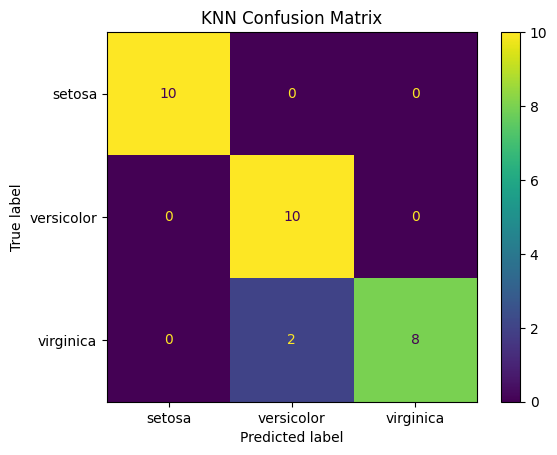


Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



,Predicted setosa,Predicted versicolor,Predicted virginica
Actual setosa,10,0,0
Actual versicolor,0,9,1
Actual virginica,0,1,9


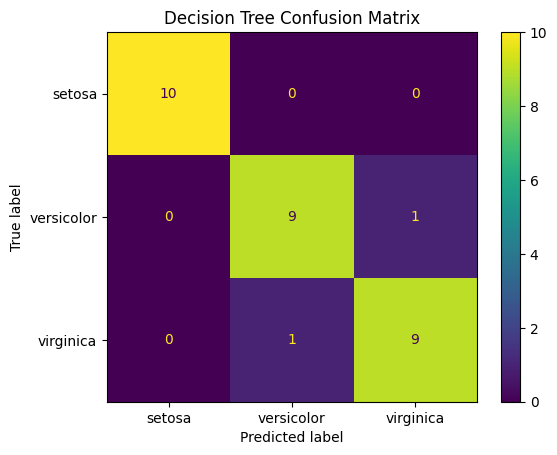


Model Accuracy Comparison:


,Model,Accuracy
0,KNN,0.933333
1,Decision Tree,0.933333


In [5]:
# SEMMA - Step 5: Assess
# Evaluate the models using the same held-out test set.

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

models = {
    "KNN": knn_model,
    "Decision Tree": tree_model
}

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred)
    })

    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)
    print(classification_report(y_test, y_pred, zero_division=0))

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["setosa", "versicolor", "virginica"]
    )

    display(
        pd.DataFrame(
            cm,
            index=["Actual setosa", "Actual versicolor", "Actual virginica"],
            columns=["Predicted setosa", "Predicted versicolor", "Predicted virginica"]
        )
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["setosa", "versicolor", "virginica"]
    ).plot()
    plt.title(f"{name} Confusion Matrix")
    plt.show()

results_df = pd.DataFrame(results)
print("\nModel Accuracy Comparison:")
display(results_df)

### Assess Stage: Results and Interpretation

Both K-Nearest Neighbors (KNN) and Decision Tree achieved 93.33% accuracy on the held-out test set, correctly classifying 28 of 30 flowers.

KNN correctly classified all 10 setosa and all 10 versicolor observations. It misclassified two virginica flowers as versicolor. Its precision, recall, and F1-score for virginica were 1.00, 0.80, and 0.89, respectively.

The Decision Tree correctly classified all 10 setosa observations and 9 observations each from versicolor and virginica. It misclassified one versicolor as virginica and one virginica as versicolor.

Both models achieved a macro-average F1-score of approximately 0.93. The Decision Tree had more balanced class-level recall in this test, while KNN classified every versicolor observation correctly. Neither model had higher overall accuracy.

These results suggest that both algorithms can classify the Iris dataset effectively on this particular split. However, the test set contains only 30 observations, so further evaluation, such as cross-validation, would be useful before drawing broader conclusions.

## Conclusion

This project applied all five SEMMA stages to the Iris flower classification task: Sample, Explore, Modify, Model, and Assess.

The dataset contained 150 observations across three equally represented species, with no missing values. Exploratory analysis showed that petal length and petal width were useful for distinguishing the species.

The data was split into 120 training observations and 30 testing observations. KNN and Decision Tree were trained and evaluated using the same split. Both achieved 93.33% test accuracy.

The experiment demonstrates how the SEMMA methodology can guide a structured machine learning workflow. The main limitation is the small test set, so additional validation would be needed to determine how reliably the models generalize to new data.